## SVC in-class problem

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV

# Load the dataset
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data'
columns = ['Id', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
data = pd.read_csv(url, names=columns, index_col='Id')



In [2]:
# Preview the data
data.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
Id,,,,,,,,,,
1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [3]:
# Check for missing values
data.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [4]:
data.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [5]:
len(data)   
#SVM is good for small sample sizes, 
#also it's a classification problem

214

In [6]:
# Separate features and target
X = data.drop('Type', axis=1)
y = data['Type']

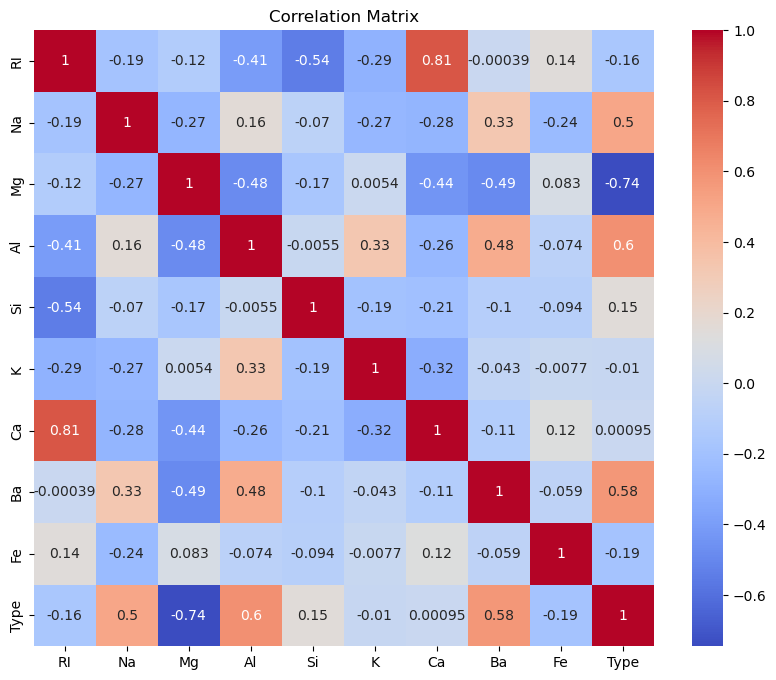

In [7]:
# Correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


The correlation matrix is a table that displays the correlation coefficients between pairs of variables in a dataset. Each cell in the matrix shows the correlation between two variables, which can range from -1 to 1:

+1 indicates a perfect positive correlation.

0 indicates no correlation.

-1 indicates a perfect negative correlation.

In [12]:
#target variable is a categorical variable (given as an integer), 
#I want to see how many samples of each category are there in the sample
from collections import Counter
print(sorted(Counter(y).items()))

[(1, 70), (2, 76), (3, 17), (5, 13), (6, 9), (7, 29)]


In [13]:
# Our sample distribution is not balanced. This can be troublesome. 
#1. in our future data, if there's a category 4 sample, we wouldn't be able to classify it correctly.
#2. if e.g. 1 and 2 are quite common in practice, or this distribution is representative 
#of the real world, then we must feed that info to the model.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
#The stratify argument in train_test_split() helps maintain the original class distribution of our dataset in the train and test splits. 
#This is crucial for building models that generalize well and provide reliable performance metrics, 
#especially when dealing with imbalanced classes in classification problems.

In [16]:
print(X_train)

          RI     Na    Mg    Al     Si     K     Ca    Ba    Fe
Id                                                             
70   1.52300  13.31  3.58  0.82  71.99  0.12  10.17  0.00  0.03
165  1.51915  12.73  1.85  1.86  72.69  0.60  10.09  0.00  0.00
148  1.51610  13.33  3.53  1.34  72.67  0.56   8.33  0.00  0.00
65   1.52172  13.48  3.74  0.90  72.01  0.18   9.61  0.00  0.07
183  1.51916  14.15  0.00  2.09  72.74  0.00  10.88  0.00  0.00
..       ...    ...   ...   ...    ...   ...    ...   ...   ...
113  1.52777  12.64  0.00  0.67  72.02  0.06  14.40  0.00  0.00
86   1.51625  13.36  3.58  1.49  72.72  0.45   8.21  0.00  0.00
213  1.51651  14.38  0.00  1.94  73.61  0.00   8.48  1.57  0.00
178  1.51937  13.79  2.41  1.19  72.76  0.00   9.77  0.00  0.00
211  1.51685  14.92  0.00  1.99  73.06  0.00   8.40  1.59  0.00

[149 rows x 9 columns]


In [17]:
# Feature Scaling using StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#print(X_train_scaled)

In [18]:
# Initialize the model
svc = SVC()

# Train the model
svc.fit(X_train_scaled, y_train)


,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [19]:
# Make predictions
y_pred = svc.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")


Accuracy: 0.7076923076923077


In [20]:
# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           1       0.65      0.81      0.72        21
           2       0.68      0.74      0.71        23
           3       0.00      0.00      0.00         5
           5       1.00      0.25      0.40         4
           6       0.67      0.67      0.67         3
           7       0.90      1.00      0.95         9

    accuracy                           0.71        65
   macro avg       0.65      0.58      0.57        65
weighted avg       0.67      0.71      0.67        65



C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

Notice the gap between macro f1 (~0.57) and weighted f1 (0.67), when macro is noticeably lower than weighted, the model does well on big classes and badly on the small classes. 
- class 3 scores 0 on everything -none of its 5 samples were classified correctly. The report doesn't tell you if the model never even tried to predict Class 3 at all, or whether it predicted but wrong! - the confusion matrix will tell you that. One hint is that the warnings that we got above: If it never predicted then you get a UndefinedMetricWarning for precision.
- Class 5 has precision 1 but recall 0.25 -again a small class
- Classes 1,2 -the big classes seems to be working well.

So although 71% accuracy seems like a good metric, when you look at the individual classes - it's biased
towards the big classes.

*The warning message you're encountering indicates that for some of the classes in your test data (y_test), your classifier did not predict any instances belonging to those classes in y_pred. As a result, metrics like precision and F-score cannot be calculated for those classes because they involve division by zero.

Why This Happens

No Predicted Instances for a Class: The classifier did not assign any test samples to certain classes present in y_test.

Class Imbalance: Some classes might be underrepresented in your dataset, causing the model to ignore them.

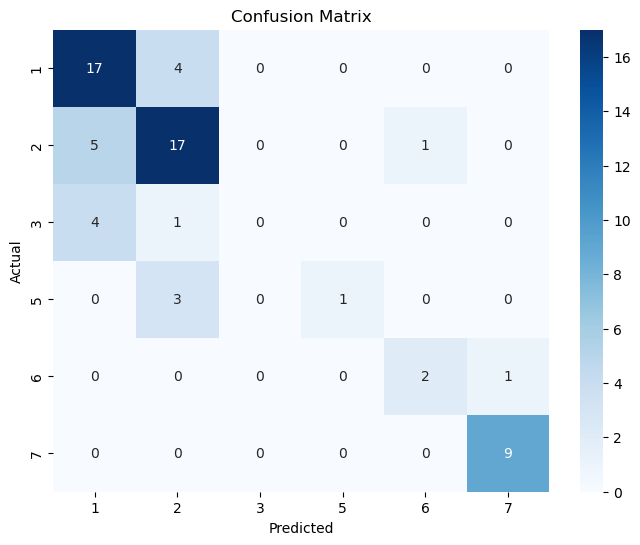

In [21]:
# Confusion matrix
#Let's first arrange the labels in order for plotting
labels = np.unique(np.concatenate([y_test, y_pred]))   # sorted

cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [25]:
#You can check for missing classifications by comparing the y_test and y_predict outcomes
from collections import Counter
print("Test set class distribution:", sorted(Counter(y_test).items()))

Test set class distribution: [(1, 21), (2, 23), (3, 5), (5, 4), (6, 3), (7, 9)]


In [27]:
print("Predicted class distribution:", sorted(Counter(y_pred).items()))

Predicted class distribution: [(np.int64(1), 26), (np.int64(2), 25), (np.int64(5), 1), (np.int64(6), 3), (np.int64(7), 10)]


We see from above e.g. 3 is in the test but not in the predicted sample

In [28]:
#Possible solution 
#Handling class imbalance

svc = SVC(class_weight='balanced')

#Resample the Dataset:
#Oversample minority classes using techniques like SMOTE.
#Undersample majority classes.

# Train the model
svc.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [30]:
# Make predictions
y_pred_bal = svc.predict(X_test_scaled)

# Calculate accuracy
accuracy_bal = accuracy_score(y_test, y_pred_bal)
print(f"Accuracy: {accuracy_bal}")


Accuracy: 0.6153846153846154


In [31]:
# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_bal))

Classification Report:
              precision    recall  f1-score   support

           1       0.71      0.71      0.71        21
           2       0.77      0.43      0.56        23
           3       0.15      0.40      0.22         5
           5       0.67      0.50      0.57         4
           6       0.67      0.67      0.67         3
           7       0.75      1.00      0.86         9

    accuracy                           0.62        65
   macro avg       0.62      0.62      0.60        65
weighted avg       0.69      0.62      0.63        65



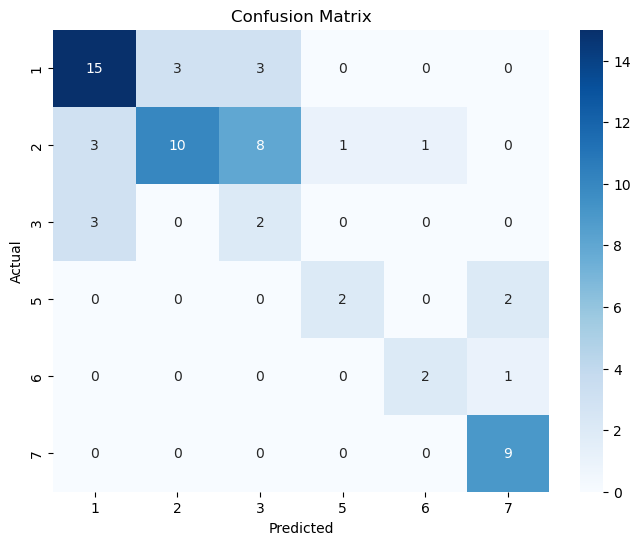

In [32]:
# Confusion matrix
cm_bal = confusion_matrix(y_test, y_pred_bal,labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_bal, annot=True, cmap='Blues', fmt='d', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In both cases with and without class balancing there's some misclassification. In reality we cannot eliminiate
misclassification to obtain a 100% accurate model. And one of the important aspects of SVM is that we allow for mis-classifications
so that in the long run it will perform better. so depending on our application we will have to decide whether to balance the classes or not.
e.g. if we want to find glass type 3 - which is rare, then the 2nd model (balanced classes) is better.

----------------

In [33]:
# 2 nd part
#_______________
#We could also use cross-validation 
#to obtain a better estimate of our model performance
#As well as tune the hyper parameters of SVC

#Using cross validation and pipeline
#------------------------------------

from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline


# Define the cross-validation strategy 
#(e.g., 5-fold cross-validation)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Create a pipeline with scaling and classifier
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(class_weight='balanced'))
])

# Perform cross-validation
cv_scores = cross_val_score(pipeline, X_train_scaled, y_train, cv=kf, scoring='accuracy')

# Print the cross-validation scores and statistics
print("Cross-validation scores for each fold:", cv_scores)
print("Mean cross-validation accuracy:", np.mean(cv_scores))
print("Standard deviation of cross-validation accuracy:", np.std(cv_scores))

Cross-validation scores for each fold: [0.6        0.66666667 0.46666667 0.53333333 0.48275862]
Mean cross-validation accuracy: 0.5498850574712644
Standard deviation of cross-validation accuracy: 0.07463869018942712


In [34]:

# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto'],
    'degree': [2, 3, 4]  # Only relevant for 'poly' kernel
}

# Initialize Grid Search
grid_search = GridSearchCV(SVC(class_weight='balanced'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# Fit the model
grid_search.fit(X_train_scaled, y_train)

# Best parameters
print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'C': 10, 'degree': 2, 'gamma': 'scale', 'kernel': 'rbf'}


Accuracy after Hyperparameter Tuning :0.78
Classification Report After Hyperparameter Tuning:
              precision    recall  f1-score   support

           1       0.70      0.90      0.79        21
           2       0.80      0.70      0.74        23
           3       1.00      0.60      0.75         5
           5       1.00      0.50      0.67         4
           6       0.67      0.67      0.67         3
           7       0.90      1.00      0.95         9

    accuracy                           0.78        65
   macro avg       0.85      0.73      0.76        65
weighted avg       0.80      0.78      0.78        65



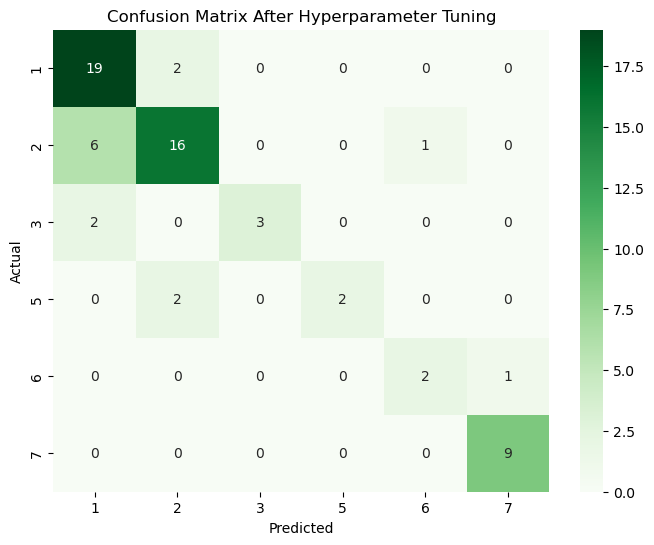

In [35]:
# Best estimator
best_svc = grid_search.best_estimator_

# Make predictions
y_pred_best = best_svc.predict(X_test_scaled)

# Calculate accuracy
accuracy_best = accuracy_score(y_test, y_pred_best)
print(f"Accuracy after Hyperparameter Tuning :{accuracy_best:.2f}")

# Classification report
print("Classification Report After Hyperparameter Tuning:")
print(classification_report(y_test, y_pred_best))

# Confusion matrix
cm_best = confusion_matrix(y_test, y_pred_best, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_best, annot=True, cmap='Greens', fmt='d',
            xticklabels=labels,
            yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix After Hyperparameter Tuning')
plt.show()


Conclusion

Using a Support Vector Classifier on the Glass Identification Dataset allows us to classify different types of glass based on their chemical composition effectively. The SVC model, especially after hyperparameter tuning, performs well in distinguishing between different glass types, which is valuable in materials science applications.

This example demonstrates the practical application of machine learning in materials science, showcasing how SVC can be used for classification tasks involving complex material properties.

Additional Notes

Imbalanced Classes: Some glass types may have fewer samples, affecting model performance. Techniques like class weighting or resampling can be considered.

Feature Selection: Further analysis might reveal that some features contribute more to the classification, allowing for dimensionality reduction.

Model Comparison: Comparing SVC with other classifiers like Random Forests or Neural Networks could provide insights into the best model for this dataset.